In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import xgboost as xgb
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [50]:
df = pd.read_csv('monthly_renewable_energy.csv')

print("--- Dataset Information ---")
print(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())

--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 2089 entries, 0 to 2088
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state_name              2089 non-null   str    
 1   state_code              2089 non-null   int64  
 2   date                    2089 non-null   str    
 3   wind_energy             2089 non-null   float64
 4   solar_energy            2089 non-null   float64
 5   other_renewable_energy  2089 non-null   float64
 6   total_renewable_energy  2089 non-null   float64
dtypes: float64(4), int64(1), str(2)
memory usage: 155.5 KB
None

--- First 5 Rows ---


,state_name,state_code,date,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,All India,99,2020-05-01,810.27,378.02,88.29,1276.58
1,All India,99,2020-06-01,6191.30,2920.54,857.31,9969.15
2,All India,99,2020-07-01,6012.11,3288.43,986.33,10286.87
3,All India,99,2020-08-01,8302.71,2902.29,1108.04,12313.04
4,All India,99,2020-09-01,4074.09,3103.13,960.84,8138.06



--- Missing Values ---
state_name                0
state_code                0
date                      0
wind_energy               0
solar_energy              0
other_renewable_energy    0
total_renewable_energy    0
dtype: int64


In [51]:
# Find top 16 regions based on total renewable energy generation
top_states = (
    df.groupby('state_name')['total_renewable_energy']
    .sum()
    .sort_values(ascending=False)
    .head(16)
    .index.tolist()
)

# Create final dataset
finaldf = df[df['state_name'].isin(top_states)].copy()

finaldf.reset_index(drop=True, inplace=True)

print("Selected Regions:", len(top_states))
print("Final Dataset Shape:", finaldf.shape)

print("\nSelected Regions:")
print(top_states)

display(finaldf.head())

Selected Regions: 16
Final Dataset Shape: (960, 7)

Selected Regions:
['All India', 'Karnataka', 'Gujarat', 'Tamil Nadu', 'Rajasthan', 'Andhra Pradesh', 'Maharashtra', 'Madhya Pradesh', 'Telangana', 'Uttar Pradesh', 'Himachal Pradesh', 'Punjab', 'Odisha', 'Chhattisgarh', 'Haryana', 'West Bengal']


,state_name,state_code,date,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,All India,99,2020-05-01,810.27,378.02,88.29,1276.58
1,All India,99,2020-06-01,6191.30,2920.54,857.31,9969.15
2,All India,99,2020-07-01,6012.11,3288.43,986.33,10286.87
3,All India,99,2020-08-01,8302.71,2902.29,1108.04,12313.04
4,All India,99,2020-09-01,4074.09,3103.13,960.84,8138.06


In [52]:
# Convert date column to datetime
finaldf['date'] = pd.to_datetime(finaldf['date'], errors='coerce')

# Remove invalid dates
finaldf.dropna(subset=['date'], inplace=True)

# 1. Ensure your dataframe is sorted chronologically
finaldf = finaldf.sort_values(['state_name', 'date']).reset_index(drop=True)

# 2. Create a continuous Cumulative Time Index (e.g., months elapsed from the start)
# If your data is monthly, this increments by 1 each month for each state
finaldf['time_idx'] = finaldf.groupby('state_name').cumcount()

# (Optional keep month for seasonal patterns)
finaldf['month'] = finaldf['date'].dt.month
finaldf['year'] = finaldf['date'].dt.year

# Encode state names
le = LabelEncoder()
finaldf['state_encoded'] = le.fit_transform(finaldf['state_name'])

# Compute min and max per state for scaling and unscaling later
finaldf['min_val'] = finaldf.groupby('state_name')['total_renewable_energy'].transform('min')
finaldf['max_val'] = finaldf.groupby('state_name')['total_renewable_energy'].transform('max')

# Add cyclical features for smoother seasonal pattern capturing
finaldf['month_sin'] = np.sin(2 * np.pi * finaldf['date'].dt.month / 12)
finaldf['month_cos'] = np.cos(2 * np.pi * finaldf['date'].dt.month / 12)

# Define features and target
features = ['state_encoded', 'year', 'month_sin', 'month_cos','month']
target = 'total_renewable_energy'

X = finaldf[features]
y = finaldf[target]

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

display(finaldf.head())

Feature Matrix Shape: (960, 5)
Target Shape: (960,)


,state_name,state_code,date,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy,time_idx,month,year,state_encoded,min_val,max_val,month_sin,month_cos
0,All India,99,2020-05-01,810.27,378.02,88.29,1276.58,0,5,2020,0,1276.58,16837.96,5.000000e-01,-8.660254e-01
1,All India,99,2020-06-01,6191.30,2920.54,857.31,9969.15,1,6,2020,0,1276.58,16837.96,1.224647e-16,-1.000000e+00
2,All India,99,2020-07-01,6012.11,3288.43,986.33,10286.87,2,7,2020,0,1276.58,16837.96,-5.000000e-01,-8.660254e-01
3,All India,99,2020-08-01,8302.71,2902.29,1108.04,12313.04,3,8,2020,0,1276.58,16837.96,-8.660254e-01,-5.000000e-01
4,All India,99,2020-09-01,4074.09,3103.13,960.84,8138.06,4,9,2020,0,1276.58,16837.96,-1.000000e+00,-1.836970e-16


In [53]:


# Min-Max normalization
denominator = (finaldf['max_val'] - finaldf['min_val']).replace(0, 1)

finaldf['target_scaled'] = (
    finaldf[target] - finaldf['min_val']
) / denominator

# Update target
y = finaldf['target_scaled']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nNormalization completed successfully!")





Training Data: (768, 5)
Testing Data: (192, 5)

Normalization completed successfully!


In [54]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)

print("=== Random Forest Performance ===")
print(f"R2 Score: {rf_r2:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAE: {rf_mae:.4f}")

=== Random Forest Performance ===
R2 Score: 0.7749
RMSE: 0.1156
MAE: 0.0868


In [55]:
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective='reg:squarederror'
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

xgb_r2 = r2_score(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

print("=== XGBoost Performance ===")
print(f"R2 Score: {xgb_r2:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"MAE: {xgb_mae:.4f}")

=== XGBoost Performance ===
R2 Score: 0.7937
RMSE: 0.1107
MAE: 0.0818


In [56]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'R2 Score': [rf_r2, xgb_r2],
    'RMSE': [rf_rmse, xgb_rmse],
    'MAE': [rf_mae, xgb_mae]
})

display(comparison)

# Select model with minimum RMSE
if rf_rmse <= xgb_rmse:
    best_model = rf_model
    best_model_name = 'Random Forest'
else:
    best_model = xgb_model
    best_model_name = 'XGBoost'

print("\nBest Model:", best_model_name)

,Model,R2 Score,RMSE,MAE
0,Random Forest,0.774920,0.115589,0.086805
1,XGBoost,0.793693,0.110664,0.081812



Best Model: XGBoost


In [57]:
state_results = []

for code in X_test['state_encoded'].unique():

    state = le.inverse_transform([int(code)])[0]

    mask = X_test['state_encoded'] == code

    if mask.sum() > 2:

        state_data = finaldf[finaldf['state_name'] == state]

        st_min = state_data['min_val'].iloc[0]
        st_max = state_data['max_val'].iloc[0]

        preds_scaled = best_model.predict(X_test.loc[mask])

        preds_actual = preds_scaled * (st_max - st_min) + st_min

        actuals = y_test.loc[mask] * (st_max - st_min) + st_min

        state_results.append({
            'State': state,
            'R2 Score': r2_score(actuals, preds_actual),
            'RMSE': np.sqrt(mean_squared_error(actuals, preds_actual)),
            'MAE': mean_absolute_error(actuals, preds_actual),
            'Samples': mask.sum()
        })

results_df = pd.DataFrame(state_results)

results_df = results_df.sort_values(
    'R2 Score',
    ascending=False
).reset_index(drop=True)

print("=== State-Wise Model Performance ===")
display(results_df)

print("\nAverage State-Wise R2:", round(results_df['R2 Score'].mean(), 4))

=== State-Wise Model Performance ===


,State,R2 Score,RMSE,MAE,Samples
0,All India,0.924440,781.610360,539.983707,8
1,Rajasthan,0.870674,128.149580,105.326456,16
2,Tamil Nadu,0.836566,396.505373,310.272247,10
3,West Bengal,0.823757,12.538978,7.312359,14
4,Odisha,0.802939,7.768842,6.629577,16
5,Karnataka,0.756843,174.897506,132.729247,6
6,Himachal Pradesh,0.754210,55.371878,43.045105,12
7,Chhattisgarh,0.730417,21.295744,16.883383,9
8,Uttar Pradesh,0.718734,45.006236,38.485925,15
9,Maharashtra,0.695896,255.590735,160.733242,15



Average State-Wise R2: 0.721


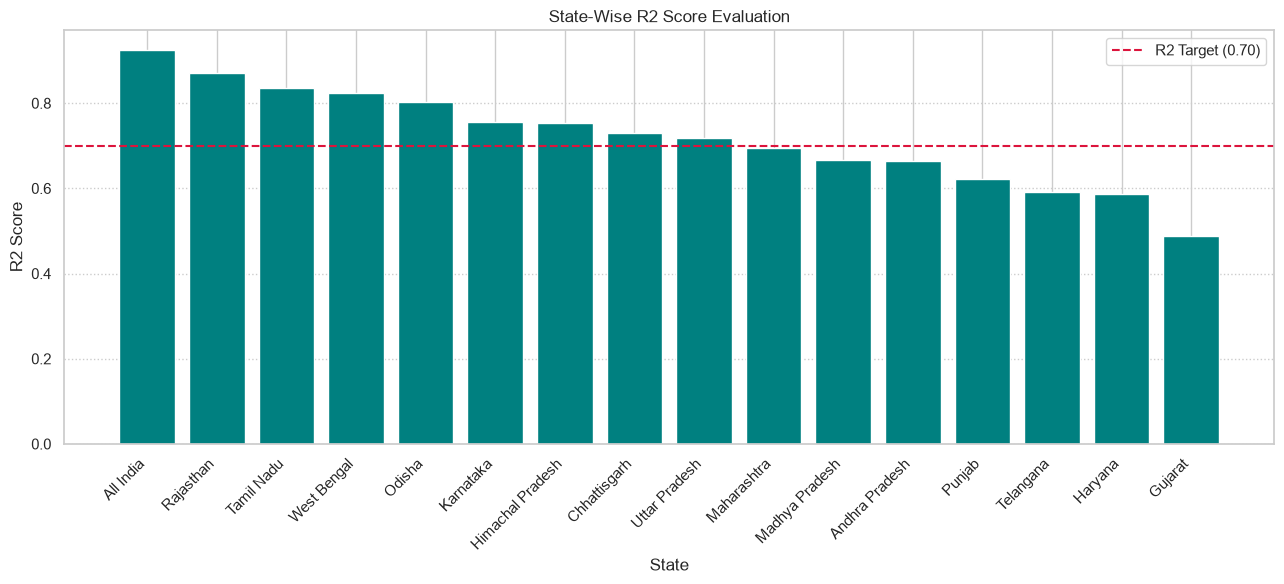

Average R2 Score: 0.721


In [58]:
r2_summary = results_df.sort_values(
    'R2 Score',
    ascending=False
)

plt.figure(figsize=(13, 6))

plt.bar(
    r2_summary['State'],
    r2_summary['R2 Score'],
    color='teal'
)

plt.axhline(
    y=0.70,
    color='crimson',
    linestyle='--',
    label='R2 Target (0.70)'
)

plt.title('State-Wise R2 Score Evaluation')
plt.xlabel('State')
plt.ylabel('R2 Score')

plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', linestyle=':')

plt.tight_layout()
plt.show()

print("Average R2 Score:", round(results_df['R2 Score'].mean(), 4))

In [59]:
last_date = finaldf['date'].max()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=58,
    freq='MS'
)

forecasts = []

# Forecast each region
for state in top_states:

    state_code = le.transform([state])[0]

    state_data = finaldf[finaldf['state_name'] == state]

    st_min = state_data['min_val'].iloc[0]
    st_max = state_data['max_val'].iloc[0]
    
    # 1. Get the maximum historical time_idx for this specific state
    last_time_idx = state_data['time_idx'].max()

    # 2. Prepare future features using a continuous time index offset
    future_months = future_dates.month
    X_future = pd.DataFrame({
        'state_encoded': state_code,
        'year' : future_dates.year,
        # 'time_idx': [last_time_idx + i + 1 for i in range(len(future_dates))],
        'month': future_dates.month,
        'month_sin': np.sin(2 * np.pi * future_months / 12),
        'month_cos': np.cos(2 * np.pi * future_months / 12)
    })

    # Predict normalized generation
    predictions_scaled = best_model.predict(X_future[features])

    # Convert predictions to actual generation
    predictions_actual = (
        predictions_scaled * (st_max - st_min)
    ) + st_min

    # Store predictions
    for date, prediction in zip(future_dates, predictions_actual):

        forecasts.append({
            'state_name': state,
            'date': date,
            'predicted_total_renewable': prediction
        })

df_forecast1 = pd.DataFrame(forecasts)

print("Forecasting Completed Successfully!")
print("Total Forecast Records:", len(df_forecast1))

display(df_forecast1.head(25))

Forecasting Completed Successfully!
Total Forecast Records: 928


,state_name,date,predicted_total_renewable
0,All India,2025-05-01,13438.279576
1,All India,2025-06-01,14568.810362
2,All India,2025-07-01,16338.337334
3,All India,2025-08-01,14381.332327
4,All India,2025-09-01,14269.326523
5,All India,2025-10-01,10334.857041
6,All India,2025-11-01,10114.728076
7,All India,2025-12-01,11380.439016
8,All India,2026-01-01,11463.824938
9,All India,2026-02-01,10959.709314


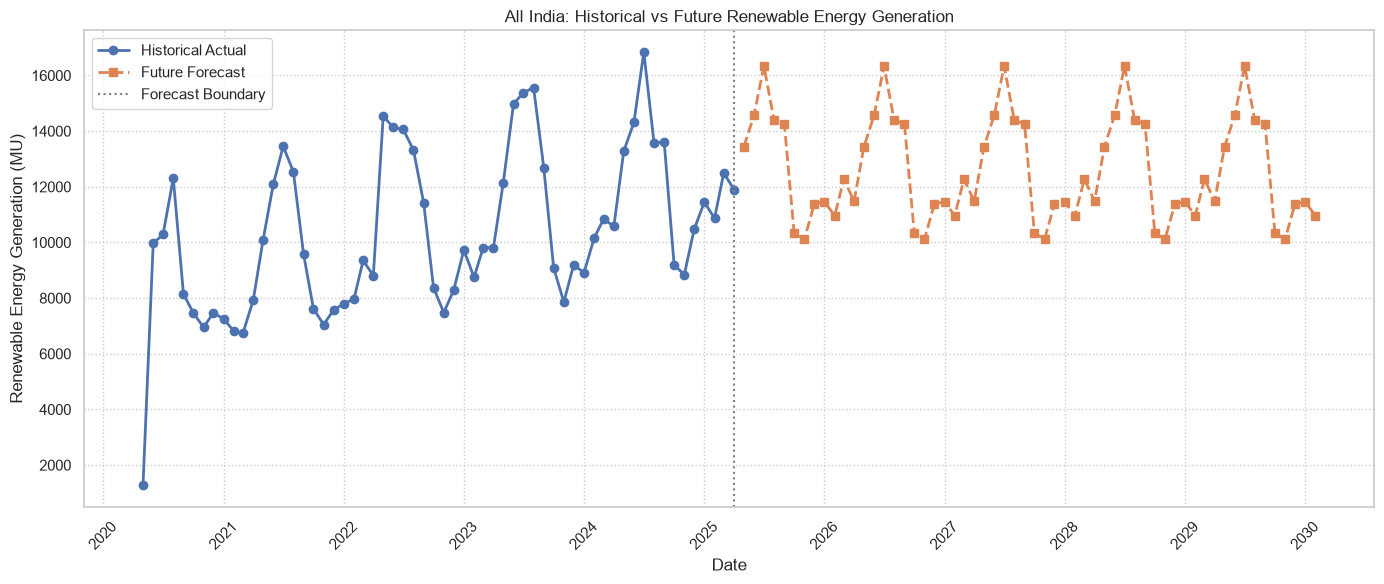

In [60]:
selected_state = 'All India'

# Historical data
hist_sel = (
    finaldf[finaldf['state_name'] == selected_state]
    .sort_values('date')
)

# Future forecast
fc_sel = (
    df_forecast1[df_forecast1['state_name'] == selected_state]
    .sort_values('date')
)

plt.figure(figsize=(14, 6))

plt.plot(
    hist_sel['date'],
    hist_sel['total_renewable_energy'],
    marker='o',
    linewidth=2,
    label='Historical Actual'
)

plt.plot(
    fc_sel['date'],
    fc_sel['predicted_total_renewable'],
    marker='s',
    linestyle='--',
    linewidth=2,
    label='Future Forecast'
)

plt.axvline(
    hist_sel['date'].max(),
    color='gray',
    linestyle=':',
    label='Forecast Boundary'
)

plt.title(
    f'{selected_state}: Historical vs Future Renewable Energy Generation'
)

plt.xlabel('Date')
plt.ylabel('Renewable Energy Generation (MU)')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()

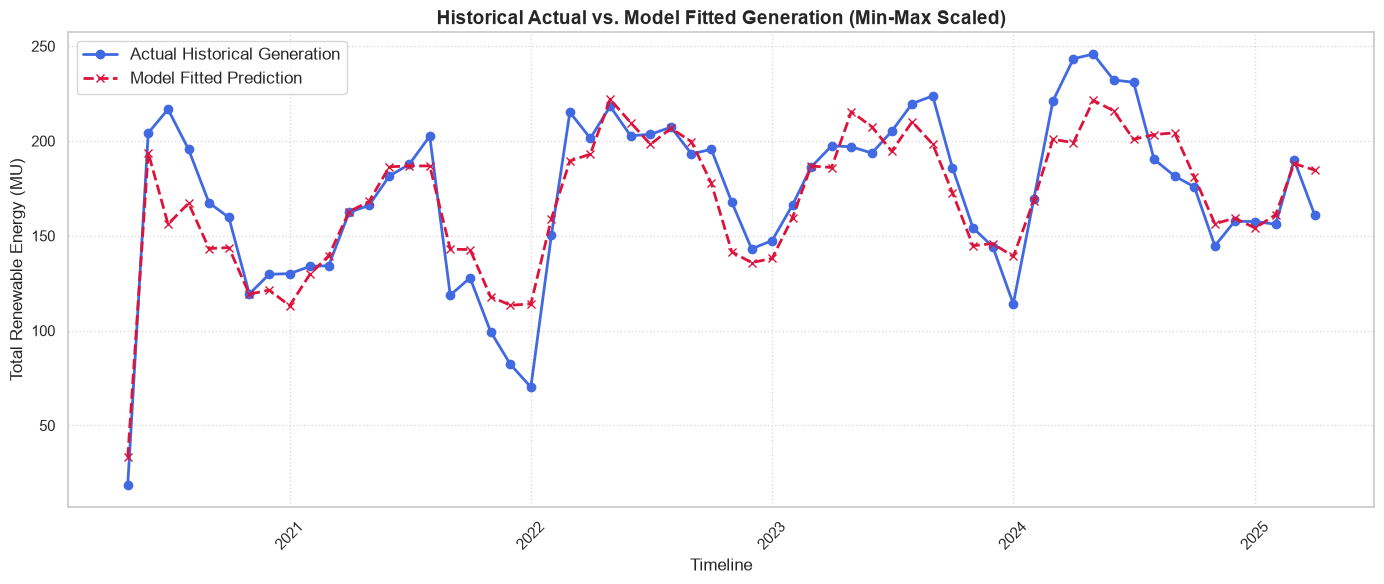

 Punjab Historical Fit R2 Score: 0.8179


In [61]:
selected_state = 'Punjab'
selected_hist = finaldf[finaldf['state_name'] == selected_state].sort_values('date').copy()

selected_min = finaldf[finaldf['state_name'] == selected_state]['min_val'].iloc[0]
selected_max = finaldf[finaldf['state_name'] == selected_state]['max_val'].iloc[0]

# Predict normalized values and unscale back to actual Megawatts (MU)
selected_preds_scaled = best_model.predict(selected_hist[features])
selected_hist['predicted_total'] = (selected_preds_scaled * (selected_max - selected_min)) + selected_min

# 2. Plot  Historical Actual vs. Model Fitted Predictions
plt.figure(figsize=(14, 6))
plt.plot(selected_hist['date'], selected_hist['total_renewable_energy'], marker='o', color='royalblue', linewidth=2, label='Actual Historical Generation')
plt.plot(selected_hist['date'], selected_hist['predicted_total'], marker='x', color='crimson', linestyle='--', linewidth=2, label='Model Fitted Prediction')

plt.title('Historical Actual vs. Model Fitted Generation (Min-Max Scaled)', fontsize=14, fontweight='bold')
plt.xlabel('Timeline', fontsize=12)
plt.ylabel('Total Renewable Energy (MU)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate and display selected states historical R2 score
selected_r2 = r2_score(selected_hist['total_renewable_energy'], selected_hist['predicted_total'])
print(f" {selected_state} Historical Fit R2 Score: {selected_r2:.4f}")

Model-3 Hybride Model

In [62]:

# 1. Fit a simple linear trend on historical data to isolate the macro trend per state
finaldf = finaldf.sort_values(['state_name', 'date']).reset_index(drop=True)

# Train a trend line for each state or globally
trend_model = LinearRegression()
trend_model.fit(finaldf[['time_idx', 'state_encoded']], finaldf['target_scaled'])
finaldf['predicted_trend'] = trend_model.predict(finaldf[['time_idx', 'state_encoded']])

# 2. Calculate seasonal residuals (what's left after removing the macro trend)
finaldf['target_residual'] = finaldf['target_scaled'] - finaldf['predicted_trend']

# 3. Train your tree model on the residuals to capture complex seasonal patterns
features = ['state_encoded', 'year','month_sin','month_cos','month']
seasonal_model = RandomForestRegressor(n_estimators=100, random_state=42)
seasonal_model.fit(finaldf[features], finaldf['target_residual'])

print("Hybrid Trend + Tree Model Trained Successfully!")



Hybrid Trend + Tree Model Trained Successfully!


In [63]:
# 4. Forecasting loop
last_date = finaldf['date'].max()
future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=58,
    freq='MS'
)


forecasts = []

for state in top_states:
    state_code = le.transform([state])[0]
    state_data = finaldf[finaldf['state_name'] == state]
    st_min = state_data['min_val'].iloc[0]
    st_max = state_data['max_val'].iloc[0]
    last_time_idx = state_data['time_idx'].max()

    # Prepare future features including cyclical month transformations
    future_months = future_dates.month
    X_future = pd.DataFrame({
        'state_encoded': state_code,
        'time_idx': [last_time_idx + i + 1 for i in range(len(future_dates))],
        'year': future_dates.year,
        'month': future_dates.month,
        'month_sin': np.sin(2 * np.pi * future_months / 12),
        'month_cos': np.cos(2 * np.pi * future_months / 12)
    })

    # Predict future trend component (handles the yearly upward growth)
    future_trend = trend_model.predict(X_future[['time_idx', 'state_encoded']])

    # Predict future seasonal residuals using the updated feature set
    future_residuals = seasonal_model.predict(X_future[['state_encoded', 'year', 'month_sin', 'month_cos','month']])

    # Combine trend + seasonality
    predictions_scaled = future_trend + future_residuals

    # Unscale predictions back to actual generation units
    predictions_actual = (predictions_scaled * (st_max - st_min)) + st_min

    # Store predictions
    for date, prediction in zip(future_dates, predictions_actual):
        forecasts.append({
            'state_name': state,
            'date': date,
            'predicted_total_renewable': prediction
        })

df_forecast = pd.DataFrame(forecasts)
print("Upgraded Hybrid Forecasting Completed Successfully!")
display(df_forecast.sample(20))

Upgraded Hybrid Forecasting Completed Successfully!


,state_name,date,predicted_total_renewable
130,Gujarat,2026-07-01,2653.997941
313,Andhra Pradesh,2027-04-01,1112.713052
882,West Bengal,2026-05-01,66.997644
636,Himachal Pradesh,2030-01-01,242.070000
47,All India,2029-04-01,14432.153718
117,Gujarat,2025-06-01,2608.884613
597,Himachal Pradesh,2026-10-01,272.189466
518,Telangana,2029-11-01,702.279164
810,Chhattisgarh,2030-01-01,156.889323
158,Gujarat,2028-11-01,2486.535077


In [64]:
from sklearn.metrics import r2_score

# 1. First, get in-sample predictions on your historical dataset to evaluate fit
finaldf['predicted_trend'] = trend_model.predict(finaldf[['time_idx', 'state_encoded']])
finaldf['predicted_residual'] = seasonal_model.predict(finaldf[features])
finaldf['predicted_scaled'] = finaldf['predicted_trend'] + finaldf['predicted_residual']

# 2. Overall R2 Score across all data points
overall_r2 = r2_score(finaldf['target_scaled'], finaldf['predicted_scaled'])
print(f"--- Overall Model R² Score: {overall_r2:.4f} ---\n")

# 3. State-wise R2 Scores dictionary & DataFrame
state_r2_results1 = []

for state in top_states:
    state_subset = finaldf[finaldf['state_name'] == state]
    
    # Ensure there is enough data to compute R2 for the state
    if len(state_subset) > 1:
        st_r2 = r2_score(state_subset['target_scaled'], state_subset['predicted_scaled'])
        state_r2_results1.append({
            'state_name': state,
            'r2_score': st_r2,
            'sample_count': len(state_subset)
        })

df_state_r2 = pd.DataFrame(state_r2_results1).sort_values(by='r2_score', ascending=False)

print("--- State-Wise R² Scores ---")
display(df_state_r2)
print("Average R2 Score:", round(df_state_r2 ['r2_score'].mean(), 4))

df_state_r2.to_csv('state_r2_scores.csv', index=False)


--- Overall Model R² Score: 0.9683 ---

--- State-Wise R² Scores ---


,state_name,r2_score,sample_count
3,Tamil Nadu,0.982577,60
0,All India,0.982511,60
9,Uttar Pradesh,0.972467,60
14,Haryana,0.970819,60
2,Gujarat,0.970381,60
10,Himachal Pradesh,0.970343,60
6,Maharashtra,0.967268,60
12,Odisha,0.959953,60
1,Karnataka,0.956632,60
13,Chhattisgarh,0.949326,60


Average R2 Score: 0.9594


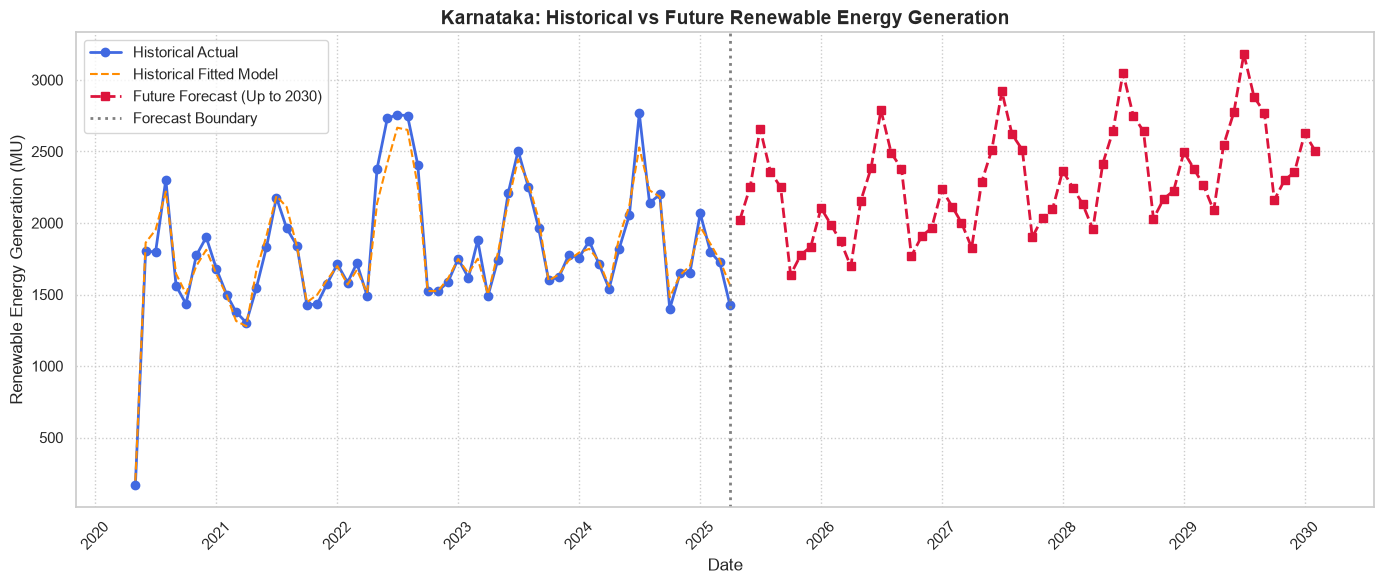

In [ ]:
selected_state = 'All India'

# 1. Historical data & model fitted calculations
hist_sel = (
    finaldf[finaldf['state_name'] == selected_state]
    .sort_values('date')
    .copy()
)

st_min = hist_sel['min_val'].iloc[0]
st_max = hist_sel['max_val'].iloc[0]

# Compute historical fitted values for visual verification
trend_preds = trend_model.predict(hist_sel[['time_idx', 'state_encoded']])
residual_preds = seasonal_model.predict(hist_sel[['state_encoded','year', 'month_sin','month_cos','month']])
hist_scaled = trend_preds + residual_preds
hist_sel['predicted_total'] = (hist_scaled * (st_max - st_min)) + st_min

# 2. Future forecast data
fc_sel = (
    df_forecast[df_forecast['state_name'] == selected_state]
    .sort_values('date')
)

# 3. Plotting
plt.figure(figsize=(14, 6))

plt.plot(
    hist_sel['date'],
    hist_sel['total_renewable_energy'],
    marker='o',
    linewidth=2,
    color='royalblue',
    label='Historical Actual'
)

plt.plot(
    hist_sel['date'],
    hist_sel['predicted_total'],
    linestyle='--',
    linewidth=1.5,
    color='darkorange',
    label='Historical Fitted Model'
)

plt.plot(
    fc_sel['date'],
    fc_sel['predicted_total_renewable'],  # Updated column name
    marker='s',
    linestyle='--',
    linewidth=2,
    color='crimson',
    label='Future Forecast (Up to 2030)'
)

plt.axvline(
    hist_sel['date'].max(),
    color='gray',
    linestyle=':',
    linewidth=2,
    label='Forecast Boundary'
)

plt.title(
    f'{selected_state}: Historical vs Future Renewable Energy Generation',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Date', fontsize=12)
plt.ylabel('Renewable Energy Generation (MU)', fontsize=12)

plt.legend(fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()

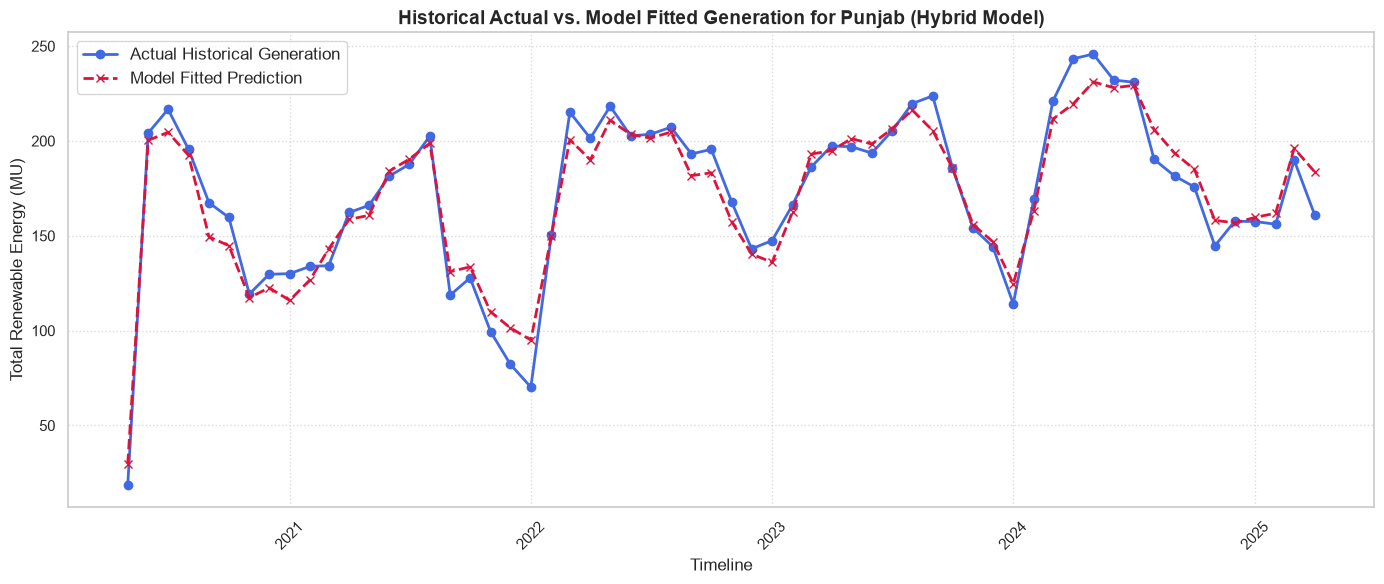

 Punjab Historical Fit R2 Score: 0.9442


In [66]:
selected_state = 'Punjab'
selected_hist = finaldf[finaldf['state_name'] == selected_state].sort_values('date').copy()

selected_min = finaldf[finaldf['state_name'] == selected_state]['min_val'].iloc[0]
selected_max = finaldf[finaldf['state_name'] == selected_state]['max_val'].iloc[0]

# 1. Predict trend and residual components using the Standard Hybrid models
trend_preds = trend_model.predict(selected_hist[['time_idx', 'state_encoded']])
residual_preds = seasonal_model.predict(selected_hist[['state_encoded', 'year', 'month_sin','month_cos','month']])
selected_preds_scaled = trend_preds + residual_preds

# Unscale back to actual Megawatts (MU)
selected_hist['predicted_total'] = (selected_preds_scaled * (selected_max - selected_min)) + selected_min

# 2. Plot Historical Actual vs. Model Fitted Predictions
plt.figure(figsize=(14, 6))
plt.plot(selected_hist['date'], selected_hist['total_renewable_energy'], marker='o', color='royalblue', linewidth=2, label='Actual Historical Generation')
plt.plot(selected_hist['date'], selected_hist['predicted_total'], marker='x', color='crimson', linestyle='--', linewidth=2, label='Model Fitted Prediction')

plt.title(f'Historical Actual vs. Model Fitted Generation for {selected_state} (Hybrid Model)', fontsize=14, fontweight='bold')
plt.xlabel('Timeline', fontsize=12)
plt.ylabel('Total Renewable Energy (MU)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate and display selected state's historical R2 score
selected_r2 = r2_score(selected_hist['total_renewable_energy'], selected_hist['predicted_total'])
print(f" {selected_state} Historical Fit R2 Score: {selected_r2:.4f}")

In [67]:
# Dates from the month after your last data till Dec 2030
last_date = finaldf['date'].max()
future_dates = pd.date_range(start=last_date + pd.offsets.MonthBegin(1),
                             end='2030-12-01', freq='MS')

results = []

for state in top_states:
    state_data = finaldf[finaldf['state_name'] == state]
    state_code = le.transform([state])[0]
    st_min = state_data['min_val'].iloc[0]
    st_max = state_data['max_val'].iloc[0]
    last_idx = state_data['time_idx'].max()

    # Input for future months
    future_months = future_dates.month
    X_future = pd.DataFrame({
        'state_encoded': state_code,
        'time_idx': [last_idx + i + 1 for i in range(len(future_dates))],
        'year': future_dates.year,
         'month': future_months,
        'month_sin': np.sin(2 * np.pi * future_months / 12),
        'month_cos': np.cos(2 * np.pi * future_months / 12)
    })

    # Prediction = trend + seasonal part
    trend = trend_model.predict(X_future[['time_idx', 'state_encoded']])
    seasonal = seasonal_model.predict(X_future[['state_encoded', 'year', 'month_sin','month_cos','month']])
    pred_scaled = trend + seasonal

    # Convert back to real values
    pred_actual = pred_scaled * (st_max - st_min) + st_min
    pred_actual = pred_actual.clip(min=0)   # no negative values

    for date, value in zip(future_dates, pred_actual):
        results.append({
            'state_name': state,
            'date': date,
            'forecast_renewable_energy': round(value, 2)
        })

forecast_df = pd.DataFrame(results)
forecast_df.to_csv('forecast_2030.csv', index=False)

print("Forecast saved!")
forecast_df.head()

Forecast saved!


,state_name,date,forecast_renewable_energy
0,All India,2025-05-01,13758.30
1,All India,2025-06-01,15541.80
2,All India,2025-07-01,16712.58
3,All India,2025-08-01,15221.77
4,All India,2025-09-01,14010.72


In [68]:
import joblib

joblib.dump(trend_model, 'trend_model.pkl')
joblib.dump(seasonal_model, 'seasonal_model.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Models saved!")

Models saved!
